# Q-Select: Tabular Q-Learning for PostgreSQL SQL Rewrite Selection

This notebook trains and tunes a tabular Q-learning agent that decides **when** to apply
semantics-preserving SQL rewrites for three target patterns:

1. Correlated scalar subqueries -> `SUBQUERY_TO_JOIN`
2. `NOT IN` on non-nullable keys -> `NOT_IN_TO_ANTI_JOIN`
3. Cross-table `OR` disjunctions -> `OR_TO_UNION`

Workflow:

1. Build a **cached reward matrix** from the database (original + each rewrite, executed once).
2. Run a multi-seed **grid search** over hyperparameters on a **validation split**.
3. Train the final agent with the best configuration.
4. Evaluate against Original PostgreSQL and Always-Rewrite baselines on a **held-out test set**.


## 0. Setup & imports

In [1]:
import time
import json
import random
import hashlib
import statistics
from dataclasses import dataclass, asdict
from itertools import product
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psycopg
from tqdm.auto import tqdm

ARTIFACT_DIR = Path("artifacts")
ARTIFACT_DIR.mkdir(exist_ok=True)


/Users/dannykhant/Code/cmkl/assignments/q-select/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Database connector & execution protocol

In [2]:
DB_CONFIG = {
    "dbname": "tpch_sf1",
    "user": "postgres",
    "password": "postgres",
    "host": "localhost",
    "port": 5433,
}


def execute_query(sql: str, timeout_sec: float = 15.0, warmups: int = 2, repeats: int = 5):
    """
    Execute query following proposal.md evaluation protocol:
    2 warm-up runs, 5 measured runs, returning (median_runtime_ms, rows, success).
    """
    try:
        with psycopg.connect(**DB_CONFIG, autocommit=True) as conn:
            with conn.cursor() as cur:
                cur.execute(f"SET statement_timeout = {int(timeout_sec * 1000)};")

                # Warm-up executions (not measured)
                for _ in range(warmups):
                    cur.execute(sql)
                    cur.fetchall()

                # Measured executions
                runtimes = []
                rows = None
                for _ in range(repeats):
                    t0 = time.perf_counter()
                    cur.execute(sql)
                    rows = cur.fetchall()
                    t1 = time.perf_counter()
                    runtimes.append((t1 - t0) * 1000.0)

                return statistics.median(runtimes), rows, True
    except Exception:
        return None, None, False


def get_planner_cardinality(sql: str) -> float | None:
    """
    Extract estimated outer/plan row count from PostgreSQL planner using EXPLAIN (FORMAT JSON).
    Takes < 1 ms without executing the query.
    """
    try:
        with psycopg.connect(**DB_CONFIG, autocommit=True) as conn:
            with conn.cursor() as cur:
                cur.execute(f"EXPLAIN (FORMAT JSON) {sql}")
                plan = cur.fetchone()[0][0]["Plan"]
                return float(plan.get("Plan Rows", 1.0))
    except Exception:
        return None


def get_buffer_diagnostics(sql: str) -> dict:
    """Collect EXPLAIN (ANALYZE, BUFFERS) diagnostic data for supporting analysis."""
    try:
        with psycopg.connect(**DB_CONFIG, autocommit=True) as conn:
            with conn.cursor() as cur:
                cur.execute(f"EXPLAIN (ANALYZE, BUFFERS, FORMAT JSON) {sql}")
                plan = cur.fetchone()[0][0]["Plan"]
                return {
                    "shared_hit_blocks": plan.get("Shared Hit Blocks", 0),
                    "shared_read_blocks": plan.get("Shared Read Blocks", 0),
                    "actual_total_time_ms": plan.get("Actual Total Time", 0.0),
                }
    except Exception:
        return {}


def results_match(rows1, rows2) -> bool:
    """Verify result set semantic equivalence (multiset comparison)."""
    if rows1 is None or rows2 is None:
        return False
    if len(rows1) != len(rows2):
        return False
    return sorted(str(r) for r in rows1) == sorted(str(r) for r in rows2)


In [3]:
# Connectivity sanity check — fail loudly instead of silently producing an empty report.
try:
    with psycopg.connect(**DB_CONFIG, autocommit=True) as _conn:
        with _conn.cursor() as _cur:
            _cur.execute("SELECT COUNT(*) FROM customer")
            _n = _cur.fetchone()[0]
    print(f"Connected to {DB_CONFIG['dbname']} @ {DB_CONFIG['host']}:{DB_CONFIG['port']} (customers={_n:,})")
except Exception as e:
    raise RuntimeError(
        f"Cannot connect to database with {DB_CONFIG}. "
        "Ensure the qselect-postgres container is running (docker compose up -d) "
        "and that DB_CONFIG['port'] matches the published host port (expected 5433)."
    ) from e


Connected to tpch_sf1 @ localhost:5433 (customers=150,000)


## 2. Verified AST rewriters (imported from `rewriter/`)

In [4]:
from rewriter import (
    ACTIONS,
    ACTION_TO_IDX,
    PATTERN_NONE,
    PATTERN_SUBQUERY,
    PATTERN_NOT_IN,
    PATTERN_OR,
    CARDINALITY_LOW,
    CARDINALITY_MEDIUM,
    CARDINALITY_HIGH,
    CARDINALITY_BUCKETS,
    apply_action,
    get_state,
    cardinality_to_bucket,
    rewrite_subquery_to_join,
    rewrite_not_in_to_anti_join,
    rewrite_or_to_union,
)

print(f"Action Space ({len(ACTIONS)} actions): {ACTIONS}")
print(f"Cardinality Buckets: LOW={CARDINALITY_LOW}, MEDIUM={CARDINALITY_MEDIUM}, HIGH={CARDINALITY_HIGH}")


Action Space (4 actions): ['DO_NOTHING', 'SUBQUERY_TO_JOIN', 'NOT_IN_TO_ANTI_JOIN', 'OR_TO_UNION']
Cardinality Buckets: LOW=0, MEDIUM=1, HIGH=2


## 3. Q-Learning agent

In [5]:
class QLearningAgent:
    """
    Tabular Q-learning agent for the single-step SQL rewrite decision.

    The update is a contextual-bandit style exponential moving average
    (`q += alpha * (reward - q)`), so no discount factor (gamma) is needed.
    """

    def __init__(self, alpha=0.2, epsilon=0.3, epsilon_decay=0.95, min_epsilon=0.05):
        self.alpha = alpha
        self.epsilon = epsilon
        self.epsilon_decay = epsilon_decay
        self.min_epsilon = min_epsilon
        self.q_table = {}  # state tuple -> np.ndarray of shape (len(ACTIONS),)

    def get_q(self, state: tuple) -> np.ndarray:
        if state not in self.q_table:
            self.q_table[state] = np.zeros(len(ACTIONS), dtype=np.float32)
        return self.q_table[state]

    def choose_action(self, state: tuple, explore: bool = True) -> int:
        if explore and random.random() < self.epsilon:
            return random.choice(range(len(ACTIONS)))
        return int(np.argmax(self.get_q(state)))

    def update(self, state: tuple, action: int, reward: float):
        q = self.get_q(state)
        q[action] += self.alpha * (reward - q[action])

    def decay_exploration(self):
        self.epsilon = max(self.min_epsilon, self.epsilon * self.epsilon_decay)


## 4. Parameterized workload (train / validation / test)

- **Training domain**:
  - correlated subqueries with *selective* outer filters (rewrites lose) **and**
    large/unfiltered outer scans (rewrites win), so both regimes are learnable;
  - `NOT IN` on non-nullable keys (nations 0-19, key lookups 1-100000);
  - cross-table `OR` over varied brands/quantities, both unfiltered and behind a
    selective `PROMO` filter.
- **Validation**: carved out of the training domain (stratified by `type`); used only for
  hyperparameter selection, never for the final report.
- **Test**: held-out templates and parameter ranges (nations 20-24, keys >= 100000,
  brands 41/42/51/52, `SUM`/`AVG`/price-threshold/PROMO templates); never used to update the Q-table.


In [6]:
def _training_domain_queries() -> list[dict]:
    queries = []

    # ── 1. Correlated Scalar Subqueries (SUBQUERY_TO_JOIN) ────────────────────
    # 1a. Selective outer filters: the rewrite usually LOSES here, so the agent
    #     can learn to keep PostgreSQL's default plan (DO_NOTHING).
    for i in range(25):
        queries.append({
            "type": "subquery_full_scan",
            "sql": f"SELECT c.c_custkey, c.c_name, (SELECT COUNT(*) FROM orders o WHERE o.o_custkey = c.c_custkey) AS cnt FROM customer c WHERE c.c_nationkey = {i % 20}"
        })
        queries.append({
            "type": "subquery_filtered",
            "sql": f"SELECT c.c_custkey, c.c_name, (SELECT COUNT(*) FROM orders o WHERE o.o_custkey = c.c_custkey) AS cnt FROM customer c WHERE c.c_custkey = {i * 100 + 1}"
        })

    # 1b. Large / unfiltered outer scans: decorrelation WINS here, so the agent
    #     can learn SUBQUERY_TO_JOIN for the high-cardinality states.
    for i in range(12):
        queries.append({
            "type": "subquery_large_scan",
            "sql": f"SELECT c.c_custkey, c.c_name, (SELECT COUNT(*) FROM orders o WHERE o.o_custkey = c.c_custkey) AS cnt FROM customer c WHERE c.c_custkey > {i * 100}"
        })
    for agg, alias in (
        ("COUNT(*)", "cnt"),
        ("SUM(o.o_totalprice)", "total_spend"),
        ("AVG(o.o_totalprice)", "avg_spend"),
        ("MAX(o.o_orderdate)", "last_order"),
    ):
        queries.append({
            "type": "subquery_unfiltered",
            "sql": f"SELECT c.c_custkey, c.c_name, (SELECT {agg} FROM orders o WHERE o.o_custkey = c.c_custkey) AS {alias} FROM customer c"
        })

    # ── 2. NOT IN Subqueries on Non-Nullable Keys (NOT_IN_TO_ANTI_JOIN) ───────
    for i in range(25):
        queries.append({
            "type": "not_in_full",
            "sql": f"SELECT c.c_custkey, c.c_name FROM customer c WHERE c.c_custkey NOT IN (SELECT o.o_custkey FROM orders o WHERE o.o_orderstatus = 'F') AND c.c_nationkey = {i % 20}"
        })
        queries.append({
            "type": "not_in_filtered",
            "sql": f"SELECT c.c_custkey, c.c_name FROM customer c WHERE c.c_custkey NOT IN (SELECT o.o_custkey FROM orders o) AND c.c_custkey = {i * 100 + 1}"
        })

    # ── 3. Multi-Table OR Disjunctions (OR_TO_UNION) ──────────────────────────
    # Vary brands/quantities so dedupe keeps many distinct examples, and cover
    # both the unfiltered and the selective-filter (high-cardinality) states.
    brands = [f"Brand#{m}{n}" for m in range(1, 6) for n in range(1, 6)]
    for i in range(12):
        b1 = brands[i]
        b2 = brands[(i + 1) % len(brands)]
        qlo = 10 + (i % 5) * 5
        qhi = 40 + (i % 5) * 5
        queries.append({
            "type": "or_cross_table",
            "sql": f"""
            SELECT l.l_orderkey, p.p_name 
            FROM lineitem l JOIN part p ON l.l_partkey = p.p_partkey
            WHERE (p.p_brand = '{b1}' AND l.l_quantity < {qlo})
               OR (p.p_brand = '{b2}' AND l.l_quantity > {qhi})
            """.strip()
        })
        queries.append({
            "type": "or_cross_table_filtered",
            "sql": f"""
            SELECT l.l_orderkey, p.p_name 
            FROM lineitem l JOIN part p ON l.l_partkey = p.p_partkey
            WHERE p.p_type LIKE 'PROMO%'
              AND ((p.p_brand = '{b1}' AND l.l_quantity < {qlo})
               OR  (p.p_brand = '{b2}' AND l.l_quantity > {qhi}))
            """.strip()
        })

    return queries


def _test_domain_queries() -> list[dict]:
    queries = []

    # ── 1. Correlated Scalar Subqueries (held-out templates) ──────────────────
    for i in range(15):
        queries.append({
            "type": "subquery_full_scan",
            "sql": f"SELECT c.c_custkey, c.c_name, (SELECT SUM(o.o_totalprice) FROM orders o WHERE o.o_custkey = c.c_custkey AND o.o_orderstatus = 'F') AS total_val FROM customer c WHERE c.c_nationkey = {20 + (i % 5)}"
        })
        queries.append({
            "type": "subquery_filtered",
            "sql": f"SELECT c.c_custkey, c.c_name, (SELECT COUNT(*) FROM orders o WHERE o.o_custkey = c.c_custkey AND o.o_totalprice > 50000) AS expensive_cnt FROM customer c WHERE c.c_custkey = {100000 + i * 200 + 1}"
        })
        queries.append({
            "type": "subquery_large_scan",
            "sql": f"SELECT c.c_custkey, c.c_name, (SELECT COUNT(*) FROM orders o WHERE o.o_custkey = c.c_custkey) AS cnt FROM customer c WHERE c.c_custkey > {50 + i * 137}"
        })
    for agg, alias in (
        ("COUNT(*)", "cnt"),
        ("SUM(o.o_totalprice)", "total_spend"),
        ("AVG(o.o_totalprice)", "avg_spend"),
    ):
        queries.append({
            "type": "subquery_unfiltered",
            "sql": f"SELECT c.c_custkey, c.c_name, (SELECT {agg} FROM orders o WHERE o.o_custkey = c.c_custkey) AS {alias} FROM customer c"
        })

    # ── 2. NOT IN Subqueries (held-out price thresholds) ──────────────────────
    for i in range(15):
        queries.append({
            "type": "not_in_full",
            "sql": f"SELECT c.c_custkey, c.c_name FROM customer c WHERE c.c_custkey NOT IN (SELECT o.o_custkey FROM orders o WHERE o.o_totalprice > 100000) AND c.c_nationkey = {20 + (i % 5)}"
        })
        queries.append({
            "type": "not_in_filtered",
            "sql": f"SELECT c.c_custkey, c.c_name FROM customer c WHERE c.c_custkey NOT IN (SELECT o.o_custkey FROM orders o WHERE o.o_orderstatus = 'F') AND c.c_custkey = {100000 + i * 200 + 1}"
        })

    # ── 3. Multi-Table OR Disjunctions (held-out brands + PROMO filter) ───────
    for i in range(15):
        b1 = f"Brand#{(i % 2) + 4}1"
        b2 = f"Brand#{(i % 2) + 4}2"
        queries.append({
            "type": "or_cross_table",
            "sql": f"""
            SELECT l.l_orderkey, p.p_name 
            FROM lineitem l JOIN part p ON l.l_partkey = p.p_partkey
            WHERE p.p_type LIKE 'PROMO%'
              AND ((p.p_brand = '{b1}' AND l.l_quantity < 15)
               OR  (p.p_brand = '{b2}' AND l.l_quantity > 45))
            """.strip()
        })

    return queries


def _dedupe(queries: list[dict]) -> list[dict]:
    """Drop duplicate SQL strings, preserving first occurrence."""
    seen = set()
    out = []
    for q in queries:
        if q["sql"] in seen:
            continue
        seen.add(q["sql"])
        out.append(q)
    return out


def generate_workloads(val_fraction: float = 0.2, seed: int = 42):
    """
    Partition queries into (train, val, test).

    The training domain is deduplicated and split stratified by `type` into
    train / validation. The test set keeps its full set of held-out queries.
    """
    rng = random.Random(seed)

    domain = _dedupe(_training_domain_queries())
    by_type: dict[str, list[dict]] = {}
    for q in domain:
        by_type.setdefault(q["type"], []).append(q)

    train, val = [], []
    for _qtype, items in sorted(by_type.items()):
        rng.shuffle(items)
        n_val = max(1, int(round(len(items) * val_fraction)))
        val.extend(items[:n_val])
        train.extend(items[n_val:])

    test = _test_domain_queries()

    rng.shuffle(train)
    rng.shuffle(val)
    rng.shuffle(test)
    return train, val, test


In [7]:
train_set, val_set, test_set = generate_workloads()

print(f"Workload partition: {len(train_set)} train, {len(val_set)} validation, {len(test_set)} held-out test queries.")
print()
print("Train types:")
print(pd.Series([q["type"] for q in train_set]).value_counts().to_string())


Workload partition: 105 train, 25 validation, 93 held-out test queries.

Train types:
not_in_filtered            20
subquery_filtered          20
subquery_full_scan         16
not_in_full                16
or_cross_table             10
or_cross_table_filtered    10
subquery_large_scan        10
subquery_unfiltered         3


### 4.1 Training query types

In [8]:
# Show one representative training query per type together with its detected state.
# The state is computed with the planner cardinality estimate, exactly as during training
# (the static estimate can land in a different bucket, e.g. large scans).
for qtype in sorted({q["type"] for q in train_set}):
    example = next(q for q in train_set if q["type"] == qtype)
    est_rows = get_planner_cardinality(example["sql"])
    pattern, has_filter, card_bucket = get_state(example["sql"], cardinality=est_rows)
    print(f"--- {qtype} ---")
    print(f"SQL:   {example['sql']}")
    print(f"State: (pattern={pattern}, has_filter={has_filter}, card_bucket={card_bucket})  [planner_rows={est_rows}]")
    print()


--- not_in_filtered ---
SQL:   SELECT c.c_custkey, c.c_name FROM customer c WHERE c.c_custkey NOT IN (SELECT o.o_custkey FROM orders o) AND c.c_custkey = 1701
State: (pattern=2, has_filter=1, card_bucket=0)  [planner_rows=1.0]

--- not_in_full ---
SQL:   SELECT c.c_custkey, c.c_name FROM customer c WHERE c.c_custkey NOT IN (SELECT o.o_custkey FROM orders o WHERE o.o_orderstatus = 'F') AND c.c_nationkey = 14
State: (pattern=2, has_filter=1, card_bucket=1)  [planner_rows=2952.0]

--- or_cross_table ---
SQL:   SELECT l.l_orderkey, p.p_name 
            FROM lineitem l JOIN part p ON l.l_partkey = p.p_partkey
            WHERE (p.p_brand = 'Brand#24' AND l.l_quantity < 25)
               OR (p.p_brand = 'Brand#25' AND l.l_quantity > 55)
State: (pattern=3, has_filter=0, card_bucket=2)  [planner_rows=111607.0]

--- or_cross_table_filtered ---
SQL:   SELECT l.l_orderkey, p.p_name 
            FROM lineitem l JOIN part p ON l.l_partkey = p.p_partkey
            WHERE p.p_type LIKE 'PROMO%'
   

## 5. Cached reward environment

The database is hit **once per unique query** (original + each of the 3 rewrites). The
resulting reward matrix is cached to disk, so training and the hyperparameter grid search
replay it with no further DB access.

Reward rules (per `proposal.md`):

- `DO_NOTHING` -> `0.0`
- action had no effect (pattern mismatch) -> `-1.0`
- incorrect result or timeout -> `-5.0`
- otherwise -> relative speedup `(T_orig - T_action) / T_orig`


In [9]:
def _cache_key(sql: str) -> str:
    return hashlib.sha1(sql.encode("utf-8")).hexdigest()


@dataclass
class QueryEval:
    type: str
    sql: str
    planner_rows: float | None
    state: tuple
    t_orig_ms: float
    actions: dict  # action name -> {"sql", "t_ms", "correct", "reward"}


def _evaluate_action(orig_sql: str, t_orig: float, orig_rows, action_name: str) -> dict:
    rewritten_sql = apply_action(orig_sql, action_name)

    # Action had no effect (pattern mismatch) -> small penalty.
    if rewritten_sql == orig_sql:
        return {"sql": rewritten_sql, "t_ms": None, "correct": False, "reward": -1.0}

    t_cand, r_cand, ok_cand = execute_query(rewritten_sql)

    # Semantic error or timeout -> heavy penalty.
    if not ok_cand or not results_match(orig_rows, r_cand):
        return {"sql": rewritten_sql, "t_ms": t_cand, "correct": False, "reward": -5.0}

    # Continuous relative speedup / regression.
    reward_value = (t_orig - t_cand) / t_orig
    return {"sql": rewritten_sql, "t_ms": t_cand, "correct": True, "reward": reward_value}


def build_reward_cache(queries: list[dict], path=None, force: bool = False) -> dict:
    """Execute original + each rewrite once per unique query and cache the reward matrix."""
    path = Path(path) if path else None
    cache = {}
    if path and path.exists() and not force:
        cache = json.loads(path.read_text())

    for q in tqdm(queries, desc="Building reward cache"):
        key = _cache_key(q["sql"])
        if key in cache:
            continue

        orig_sql = q["sql"]
        t_orig, r_orig, ok_orig = execute_query(orig_sql)
        if not ok_orig:
            continue

        planner_rows = get_planner_cardinality(orig_sql)
        state = get_state(orig_sql, cardinality=planner_rows)

        actions = {
            "DO_NOTHING": {"sql": orig_sql, "t_ms": t_orig, "correct": True, "reward": 0.0}
        }
        for action_name in ("SUBQUERY_TO_JOIN", "NOT_IN_TO_ANTI_JOIN", "OR_TO_UNION"):
            actions[action_name] = _evaluate_action(orig_sql, t_orig, r_orig, action_name)

        cache[key] = {
            "type": q["type"],
            "sql": orig_sql,
            "planner_rows": planner_rows,
            "state": list(state),
            "t_orig_ms": t_orig,
            "actions": actions,
        }

    if path:
        path.parent.mkdir(parents=True, exist_ok=True)
        path.write_text(json.dumps(cache, indent=2))
    return cache


def reward(cache_entry: dict, action_name: str) -> float:
    return float(cache_entry["actions"][action_name]["reward"])


def state_of(cache_entry: dict) -> tuple:
    return tuple(cache_entry["state"])


In [10]:
CACHE_PATH = ARTIFACT_DIR / "reward_cache_train_val.json"
cache = build_reward_cache(train_set + val_set, path=CACHE_PATH)
print(f"Cached {len(cache)} unique train/validation queries -> {CACHE_PATH}")


Building reward cache: 100%|██████████| 130/130 [00:00<00:00, 378127.27it/s]

Cached 130 unique train/validation queries -> artifacts/reward_cache_train_val.json


## 6. Training loop

In [11]:
@dataclass
class HyperParameters:
    alpha: float = 0.2
    epsilon: float = 0.35
    epsilon_decay: float = 0.92
    min_epsilon: float = 0.05
    num_episodes: int = 5


def train_agent(hparams: HyperParameters, cache: dict, train_queries: list[dict], seed: int = 0):
    """Pure cache-replay training loop. Returns (agent, episode_rewards)."""
    agent = QLearningAgent(
        alpha=hparams.alpha,
        epsilon=hparams.epsilon,
        epsilon_decay=hparams.epsilon_decay,
        min_epsilon=hparams.min_epsilon,
    )
    random.seed(seed)
    np.random.seed(seed)

    keys = [_cache_key(q["sql"]) for q in train_queries]
    history = []
    for _ in range(hparams.num_episodes):
        random.shuffle(keys)
        total = 0.0
        for key in keys:
            entry = cache.get(key)
            if entry is None:
                continue
            state = state_of(entry)
            action_idx = agent.choose_action(state, explore=True)
            r = reward(entry, ACTIONS[action_idx])
            agent.update(state, action_idx, r)
            total += r
        agent.decay_exploration()
        history.append(total)
    return agent, history


## 7. Hyperparameter tuning (grid search)

We search the grid with multiple seeds and select by **mean greedy reward on the validation set**
(the deployed policy's performance — no exploration, no Q-table updates).

**How to read the results.** This environment is a *deterministic contextual bandit*: every
cached `(state, action)` pair has a fixed reward. Tabular Q-learning's update
`q += alpha * (reward - q)` converges to the **mean reward per `(state, action)`**, so the greedy
policy is the per-state `argmax` of those means. That argmax is **independent of
`alpha`/`epsilon`** once every action has been sampled, so most configurations tie at the best
value. The only variation comes from configurations that *under-explore* (few episodes and/or a
fast `epsilon_decay`) and never sample a positive-reward action. Hyperparameters therefore affect
**convergence speed**, not the final policy — which is why the selection mainly reduces to "does
it explore enough to converge?".


In [12]:
def greedy_val_reward(agent: QLearningAgent, cache: dict, val_queries: list[dict]) -> float:
    """Mean reward of the greedy (deployment) policy on the validation set."""
    rewards = []
    for q in val_queries:
        entry = cache.get(_cache_key(q["sql"]))
        if entry is None:
            continue
        state = state_of(entry)
        action_idx = agent.choose_action(state, explore=False)
        rewards.append(reward(entry, ACTIONS[action_idx]))
    return float(np.mean(rewards)) if rewards else float("nan")


GRID = {
    "alpha": [0.05, 0.1, 0.2, 0.3, 0.5],
    "epsilon": [0.2, 0.35, 0.5],
    "epsilon_decay": [0.85, 0.92, 0.95],
    "min_epsilon": [0.05, 0.1],
    "num_episodes": [3, 5, 10],
}
TUNING_SEEDS = [0, 1, 2]


def grid_search(grid: dict, cache: dict, train_queries, val_queries, seeds=TUNING_SEEDS) -> pd.DataFrame:
    param_names = list(grid.keys())
    records = []
    for combo in tqdm(list(product(*grid.values())), desc="Hyperparameter grid search"):
        params = dict(zip(param_names, combo))
        scores = []
        for seed in seeds:
            agent, _ = train_agent(HyperParameters(**params), cache, train_queries, seed=seed)
            scores.append(greedy_val_reward(agent, cache, val_queries))
        records.append({
            **params,
            "val_reward_mean": float(np.mean(scores)),
            "val_reward_std": float(np.std(scores)),
        })
    return pd.DataFrame(records)


In [13]:
tuning_df = grid_search(GRID, cache, train_set, val_set)

# Deterministic tie-break: most configurations converge to the same (optimal) policy, so
# prefer more training episodes, then higher alpha, then lower epsilon instead of row order.
tuning_df = tuning_df.sort_values(
    ["val_reward_mean", "num_episodes", "alpha", "epsilon"],
    ascending=[False, False, False, True],
).reset_index(drop=True)

best_row = tuning_df.iloc[0]
best_hp = HyperParameters(
    alpha=float(best_row["alpha"]),
    epsilon=float(best_row["epsilon"]),
    epsilon_decay=float(best_row["epsilon_decay"]),
    min_epsilon=float(best_row["min_epsilon"]),
    num_episodes=int(best_row["num_episodes"]),
)

max_score = tuning_df["val_reward_mean"].max()
n_at_max = int((tuning_df["val_reward_mean"].round(6) == round(float(max_score), 6)).sum())
n_distinct = int(tuning_df["val_reward_mean"].round(6).nunique())

print(f"Evaluated {len(tuning_df)} configurations x {len(TUNING_SEEDS)} seeds.")
print(f"Distinct validation scores: {n_distinct} / {len(tuning_df)} "
      f"— {n_at_max} configurations reach the best value ({max_score:.4f}).")
print(
    "Why so many ties: cached rewards are deterministic, so Q-learning converges to the mean "
    "reward per (state, action) and the greedy policy is the same for every configuration that "
    "converges. Variation only comes from configurations that under-explore (few episodes / "
    "fast epsilon decay) and miss a positive-reward action."
)

print("\nValidation reward by number of episodes:")
by_episodes = (
    tuning_df.assign(val_reward_mean=tuning_df["val_reward_mean"].round(4))
    .groupby("num_episodes")["val_reward_mean"]
    .agg(["min", "max", "mean", "count"])
)
print(by_episodes.to_string())

print("\nDistribution of validation scores (all configurations):")
print(
    tuning_df["val_reward_mean"].round(6).value_counts().sort_index(ascending=False).to_string()
)

print(f"\nBest validation reward: {best_row['val_reward_mean']:.4f} (+/- {best_row['val_reward_std']:.4f})")
print("Best hyperparameters (converged config, tie-broken by more episodes):")
print(f"  alpha={best_hp.alpha}, epsilon={best_hp.epsilon}, "
      f"epsilon_decay={best_hp.epsilon_decay}, min_epsilon={best_hp.min_epsilon}, "
      f"num_episodes={best_hp.num_episodes}")
tuning_df.head(10)


Hyperparameter grid search: 100%|██████████| 270/270 [00:00<00:00, 375.38it/s]

Evaluated 270 configurations x 3 seeds.
Distinct validation scores: 6 / 270 — 85 configurations reach the best value (0.3812).
Why so many ties: cached rewards are deterministic, so Q-learning converges to the mean reward per (state, action) and the greedy policy is the same for every configuration that converges. Variation only comes from configurations that under-explore (few episodes / fast epsilon decay) and miss a positive-reward action.

Validation reward by number of episodes:
                 min     max      mean  count
num_episodes                                 
3             0.3252  0.3762  0.367789     90
5             0.3713  0.3812  0.376233     90
10            0.3711  0.3812  0.378382     90

Distribution of validation scores (all configurations):
val_reward_mean
0.381161    85
0.376247    89
0.371332    65
0.371149    11
0.366417    10
0.325169    10

Best validation reward: 0.3812 (+/- 0.0000)
Best hyperparameters (converged config, tie-broken by more episodes):
  a

,alpha,epsilon,epsilon_decay,min_epsilon,num_episodes,val_reward_mean,val_reward_std
0,0.5,0.20,0.92,0.05,10,0.381161,0.0
1,0.5,0.20,0.92,0.10,10,0.381161,0.0
2,0.5,0.20,0.95,0.05,10,0.381161,0.0
3,0.5,0.20,0.95,0.10,10,0.381161,0.0
4,0.5,0.35,0.85,0.10,10,0.381161,0.0
5,0.5,0.50,0.85,0.05,10,0.381161,0.0
6,0.5,0.50,0.85,0.10,10,0.381161,0.0
7,0.5,0.50,0.92,0.05,10,0.381161,0.0
8,0.5,0.50,0.92,0.10,10,0.381161,0.0
9,0.5,0.50,0.95,0.05,10,0.381161,0.0


### 7.1 Hyperparameter sensitivity

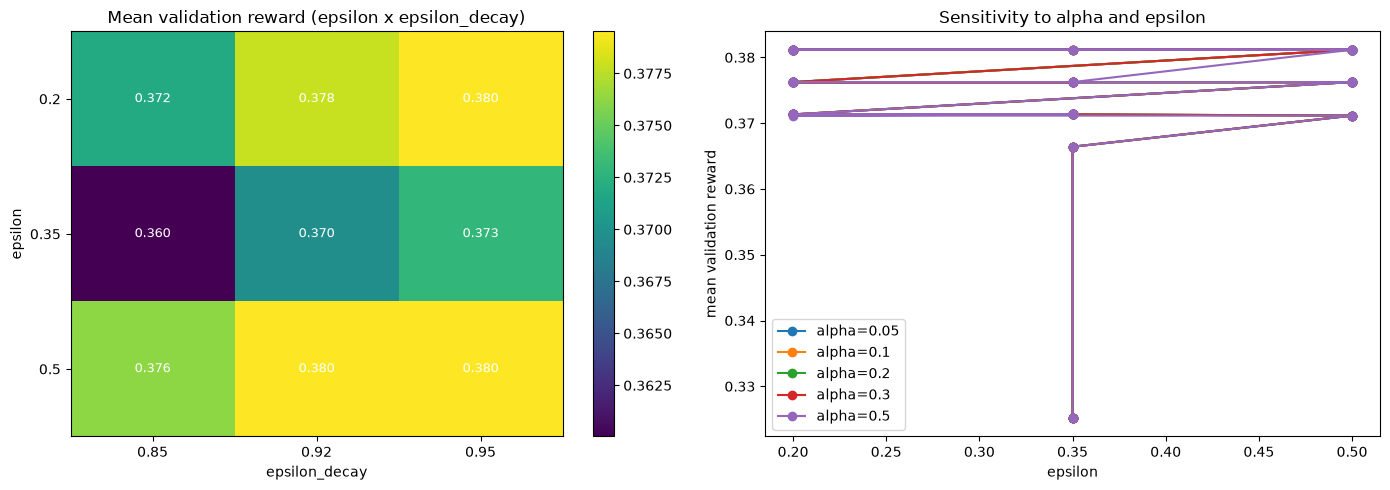

In [14]:
pivot = tuning_df.pivot_table(
    index="epsilon", columns="epsilon_decay", values="val_reward_mean", aggfunc="mean"
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

im = axes[0].imshow(pivot.values, aspect="auto", cmap="viridis")
axes[0].set_xticks(range(len(pivot.columns)))
axes[0].set_xticklabels(pivot.columns)
axes[0].set_yticks(range(len(pivot.index)))
axes[0].set_yticklabels(pivot.index)
axes[0].set_xlabel("epsilon_decay")
axes[0].set_ylabel("epsilon")
axes[0].set_title("Mean validation reward (epsilon x epsilon_decay)")
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        axes[0].text(j, i, f"{pivot.values[i, j]:.3f}", ha="center", va="center", color="white", fontsize=9)
fig.colorbar(im, ax=axes[0])

for alpha_val, grp in tuning_df.groupby("alpha"):
    axes[1].plot(grp["epsilon"], grp["val_reward_mean"], marker="o", label=f"alpha={alpha_val}")
axes[1].set_xlabel("epsilon")
axes[1].set_ylabel("mean validation reward")
axes[1].set_title("Sensitivity to alpha and epsilon")
axes[1].legend()

plt.tight_layout()
plt.show()


## 8. Final agent (best hyperparameters)

In [15]:
final_agent = None
best_seed = None
best_val = -np.inf
final_history = None

for seed in TUNING_SEEDS:
    agent, history = train_agent(best_hp, cache, train_set, seed=seed)
    score = greedy_val_reward(agent, cache, val_set)
    if score > best_val:
        final_agent, best_seed, best_val, final_history = agent, seed, score, history

print(f"Final agent trained with best config (seed={best_seed}, val reward={best_val:.4f}).")
print(f"Visited states: {len(final_agent.q_table)}")


Final agent trained with best config (seed=0, val reward=0.3812).
Visited states: 8


## 9. Evaluation on held-out test set

In [16]:
def evaluate_policy(agent: QLearningAgent, cache: dict, test_queries: list[dict]) -> pd.DataFrame:
    heuristic_for_pattern = {
        PATTERN_SUBQUERY: "SUBQUERY_TO_JOIN",
        PATTERN_NOT_IN: "NOT_IN_TO_ANTI_JOIN",
        PATTERN_OR: "OR_TO_UNION",
    }

    records = []
    for q in test_queries:
        entry = cache.get(_cache_key(q["sql"]))
        if entry is None:
            continue

        state = state_of(entry)
        pattern, has_selective_filter, card_bucket = state
        t_orig = float(entry["t_orig_ms"])

        # Baseline 2: Always Rewrite (Heuristic)
        heur_name = heuristic_for_pattern.get(pattern, "DO_NOTHING")
        heur = entry["actions"][heur_name]
        heur_correct = bool(heur["correct"])
        t_heur = float(heur["t_ms"]) if (heur_correct and heur["t_ms"] is not None) else t_orig

        # Condition 3: Q-Learning Agent (greedy policy, no updates)
        action_idx = agent.choose_action(state, explore=False)
        agent_name = ACTIONS[action_idx]
        chosen = entry["actions"][agent_name]
        agent_correct = bool(chosen["correct"])
        t_agent = float(chosen["t_ms"]) if (agent_correct and chosen["t_ms"] is not None) else t_orig

        heur_regressed = t_heur > t_orig * 1.05
        agent_avoided_regression = heur_regressed and (agent_name == "DO_NOTHING" or t_agent <= t_orig)

        records.append({
            "type": q["type"],
            "pattern": pattern,
            "card_bucket": card_bucket,
            "has_filter": has_selective_filter,
            "t_orig_ms": t_orig,
            "t_heur_ms": t_heur,
            "t_agent_ms": t_agent,
            "agent_choice": agent_name,
            "heur_regressed": heur_regressed,
            "agent_avoided_regression": agent_avoided_regression,
            "agent_correct": agent_correct,
        })

    return pd.DataFrame(records)


def report(df: pd.DataFrame):
    print("\n" + "=" * 70)
    print("Q-SELECT EXPERIMENTAL EVALUATION REPORT (TPC-H SF 1.0)")
    print("=" * 70)

    tot_orig = df["t_orig_ms"].sum()
    tot_heur = df["t_heur_ms"].sum()
    tot_agent = df["t_agent_ms"].sum()

    print(f"\n1. Overall Runtime Summary (across {len(df)} test queries):")
    print(f"   - Baseline 1 (Original PostgreSQL):        {tot_orig:10.2f} ms")
    print(f"   - Baseline 2 (Always Rewrite Heuristic):   {tot_heur:10.2f} ms")
    print(f"   - Condition 3 (Q-Learning Agent):          {tot_agent:10.2f} ms")
    print(f"   ------------------------------------------------------------")
    print(f"   Speedup of Agent vs. Original PostgreSQL:  {tot_orig / tot_agent:6.2f}x")
    print(f"   Speedup of Agent vs. Always Rewrite:       {tot_heur / tot_agent:6.2f}x")

    print(f"\n2. Hypothesis 1 — Regression Avoidance:")
    num_heur_regressions = int(df["heur_regressed"].sum())
    num_avoided = int(df["agent_avoided_regression"].sum())
    print(f"   - Total queries where Heuristic regressed: {num_heur_regressions}")
    print(f"   - Regressions successfully avoided by Agent: {num_avoided}")
    if num_heur_regressions > 0:
        print(f"   - Regression Avoidance Rate:               {num_avoided / num_heur_regressions * 100:.1f}%")

    print(f"\n3. Hypothesis 2 — Performance vs. Original PostgreSQL:")
    num_speedups = int((df["t_agent_ms"] < df["t_orig_ms"] * 0.95).sum())
    num_neutral = int(df["t_agent_ms"].between(df["t_orig_ms"] * 0.95, df["t_orig_ms"] * 1.05).sum())
    num_regressed = int((df["t_agent_ms"] > df["t_orig_ms"] * 1.05).sum())
    print(f"   - Queries with significant speedup (> 5%):  {num_speedups}")
    print(f"   - Queries with neutral runtime (within 5%): {num_neutral}")
    print(f"   - Queries with regression (> 5%):          {num_regressed}")

    print(f"\n4. Hypothesis 3 — Semantic Correctness:")
    correct_count = int(df["agent_correct"].sum())
    print(f"   - Equivalence Verified:                    {correct_count} / {len(df)} ({correct_count / len(df) * 100:.1f}%)")
    assert correct_count == len(df), "SEMANTIC REGRESSION DETECTED: Not all rewrites produced identical result sets!"
    print("   - SUCCESS: 100% semantic equivalence verified across all test executions.")

    print("\n5. Performance Breakdown by Query Pattern:")
    grouped = df.groupby("type")[["t_orig_ms", "t_heur_ms", "t_agent_ms"]].sum()
    grouped["agent_speedup"] = grouped["t_orig_ms"] / grouped["t_agent_ms"]
    print(grouped.to_string())
    print("=" * 70)
    return grouped


In [17]:
TEST_CACHE_PATH = ARTIFACT_DIR / "reward_cache_test.json"
test_cache = build_reward_cache(test_set, path=TEST_CACHE_PATH)
print(f"Cached {len(test_cache)} unique test queries -> {TEST_CACHE_PATH}")

df = evaluate_policy(final_agent, test_cache, test_set)
grouped = report(df)


Building reward cache: 100%|██████████| 93/93 [00:00<00:00, 816046.59it/s]

Cached 60 unique test queries -> artifacts/reward_cache_test.json

Q-SELECT EXPERIMENTAL EVALUATION REPORT (TPC-H SF 1.0)

1. Overall Runtime Summary (across 93 test queries):
   - Baseline 1 (Original PostgreSQL):          22303.96 ms
   - Baseline 2 (Always Rewrite Heuristic):     14427.12 ms
   - Condition 3 (Q-Learning Agent):             9550.81 ms
   ------------------------------------------------------------
   Speedup of Agent vs. Original PostgreSQL:    2.34x
   Speedup of Agent vs. Always Rewrite:         1.51x

2. Hypothesis 1 — Regression Avoidance:
   - Total queries where Heuristic regressed: 25
   - Regressions successfully avoided by Agent: 25
   - Regression Avoidance Rate:               100.0%

3. Hypothesis 2 — Performance vs. Original PostgreSQL:
   - Queries with significant speedup (> 5%):  48
   - Queries with neutral runtime (within 5%): 45
   - Queries with regression (> 5%):          0

4. Hypothesis 3 — Semantic Correctness:
   - Equivalence Verified:       

### 9.1 Result plots

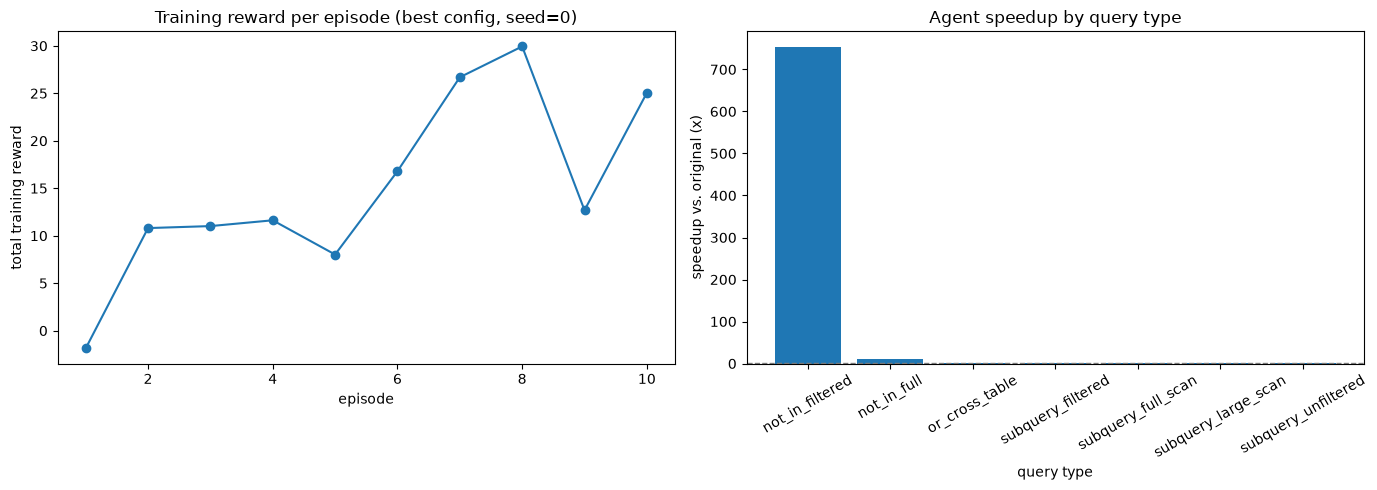

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(range(1, len(final_history) + 1), final_history, marker="o")
axes[0].set_xlabel("episode")
axes[0].set_ylabel("total training reward")
axes[0].set_title(f"Training reward per episode (best config, seed={best_seed})")

axes[1].bar(grouped.index, grouped["agent_speedup"])
axes[1].axhline(1.0, color="gray", linestyle="--", linewidth=1)
axes[1].set_xlabel("query type")
axes[1].set_ylabel("speedup vs. original (x)")
axes[1].set_title("Agent speedup by query type")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()


## 10. Persist the trained Q-table

In [19]:
Q_TABLE_PATH = ARTIFACT_DIR / "q_table.json"
q_payload = {
    "meta": {
        "actions": ACTIONS,
        "hyperparameters": asdict(best_hp),
        "seed": best_seed,
        "validation_reward": best_val,
    },
    "q_table": {
        ",".join(map(str, state)): q_values.tolist()
        for state, q_values in final_agent.q_table.items()
    },
}
Q_TABLE_PATH.write_text(json.dumps(q_payload, indent=2))
print(f"Saved trained Q-table -> {Q_TABLE_PATH}")


Saved trained Q-table -> artifacts/q_table.json
